# IIC2115 - Extracción de datos: Web scraping y APIs

## Capítulo 4, Sesión 09/11  

En esta sesión aprenderemos a obtener datos desde la web usando dos técnicas:
1. **Web scraping**: extraer datos directamente del HTML de una página web.
2. **APIs**: pedir datos a un servicio de forma estructurada.

Ambas técnicas producen datos que luego almacenaremos en una base de datos SQLite.


## 1. ¿Qué es Web Scraping?

Es el proceso de extraer datos de una página web de forma automatizada. La página está escrita en HTML, y nosotros "rascamos" la información que necesitamos.

**Analogía**: imaginen que quieren los datos de una tabla que aparece en Wikipedia. Podrían copiar y pegar a mano, pero si la tabla tiene 500 filas, eso no escala. El scraping automatiza ese proceso.

### Dos herramientas en Python:

- `pd.read_html(url)`: la forma más simple. Lee todas las tablas HTML de una página y las convierte en DataFrames.
- `BeautifulSoup`: más flexible. Permite navegar cualquier elemento del HTML (títulos, links, párrafos, listas).

Para aprender y practicar: https://www.geeksforgeeks.org/python/python-web-scraping-tutorial/


## 2. Scraping con **pd.read_html()** --> lo más simple

Una sola línea lee todas las tablas de una página web.

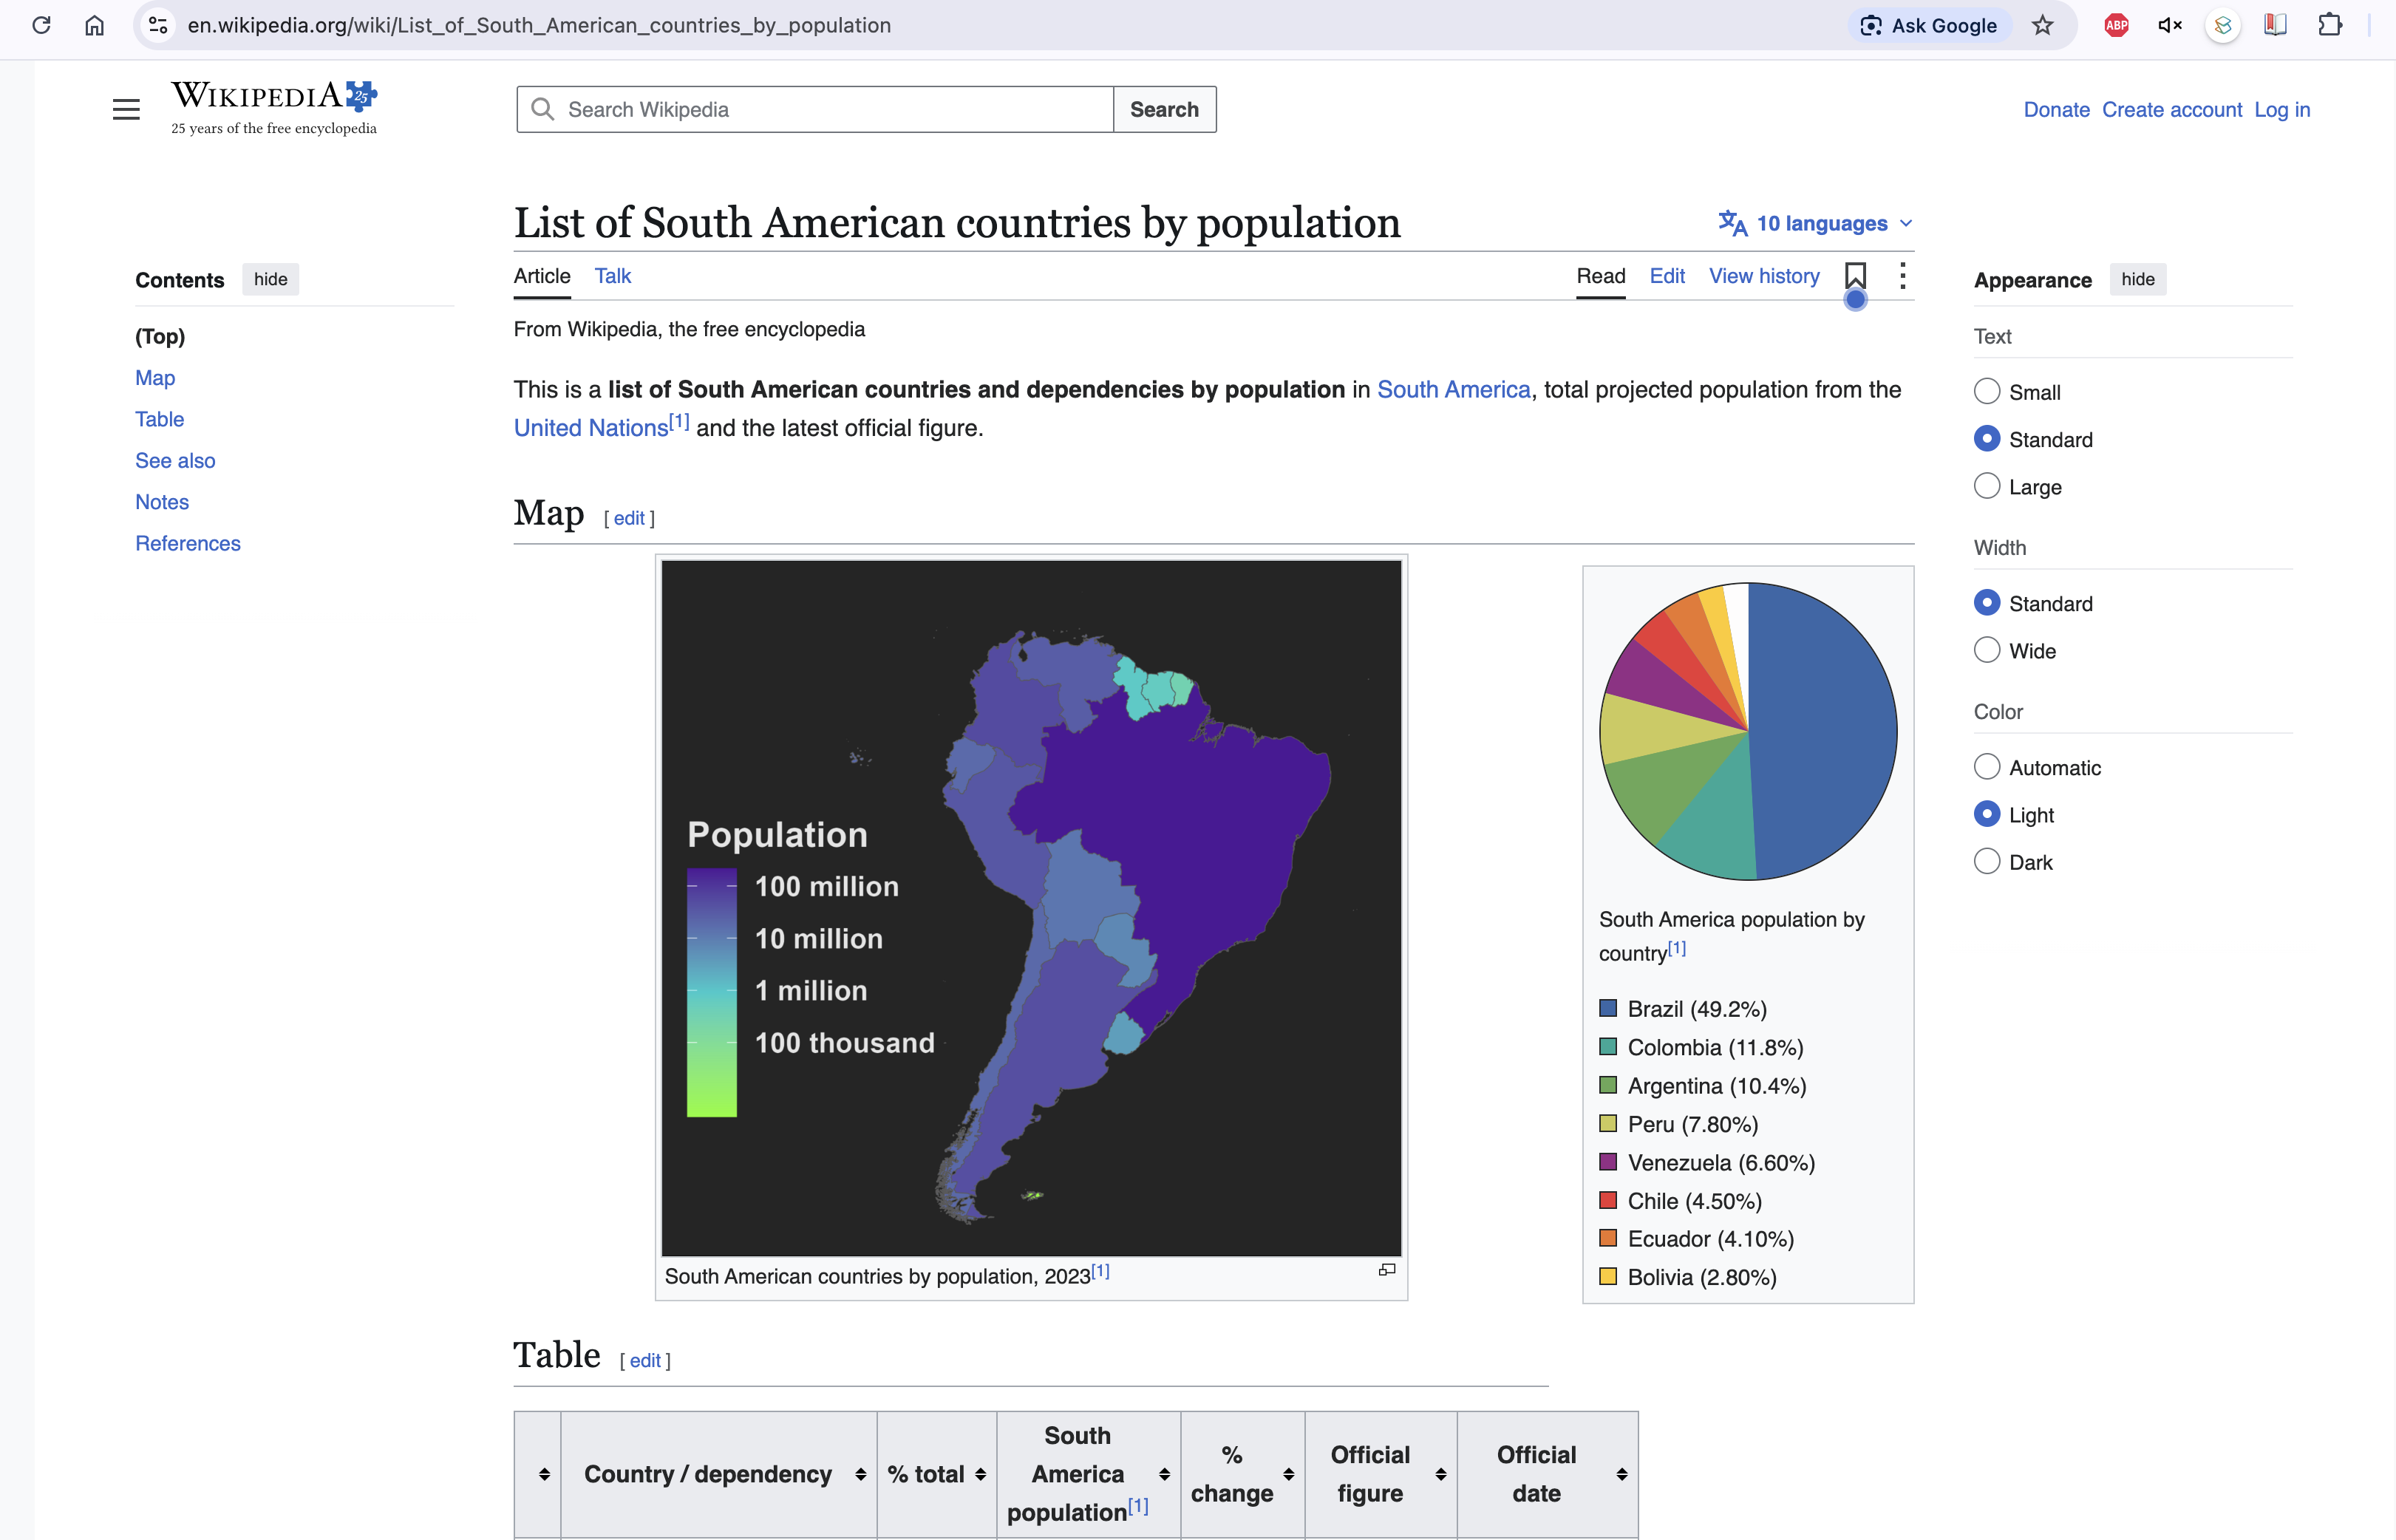


In [ ]:
# @title
import pandas as pd

# leer todas las tablas de la página de Wikipedia agregando un User-Agent para evitar el error 403
url = "https://en.wikipedia.org/wiki/List_of_South_American_countries_by_population"
tablas = pd.read_html(url, storage_options={'User-Agent': 'Mozilla/5.0'})

print(f"tablas encontradas en la página: {len(tablas)}")

In [ ]:
# @title
# explorar qué contiene cada tabla
for i, t in enumerate(tablas):
    print(f"tabla {i}: {t.shape[0]} filas x {t.shape[1]} columnas")
    print(f"  columnas: {list(t.columns)[:5]}...")
    print()

In [ ]:
# @title
# seleccionar la tabla principal
df = tablas[0]
df.head()

**¿Qué pasó?** `pd.read_html()` recorrió todo el HTML, encontró las etiquetas `<table>`, y convirtió cada una en un DataFrame.

Los datos scrapeados casi siempre necesitan limpieza: columnas con nombres raros, filas extra, tipos incorrectos.

In [ ]:
# @title
# limpieza básica
df.columns = [col.strip() for col in df.columns]
df.dtypes

---
## 3. Scraping con **BeautifulSoup** --> más flexible

BeautifulSoup permite navegar cualquier estructura HTML, no solo tablas.

**Importante**: algunos sitios bloquean solicitudes sin un header `User-Agent` (piensan que es un bot). Siempre incluirlo.

In [ ]:
# @title
import requests
from bs4 import BeautifulSoup

# paso 1: descargar el HTML de la página
url = "https://en.wikipedia.org/wiki/Chile"
headers = {"User-Agent": "Mozilla/5.0"}
response = requests.get(url, headers=headers)
print(f"código de respuesta: {response.status_code}")  # 200 = OK

In [ ]:
# @title
# paso 2: crear el objeto BeautifulSoup
soup = BeautifulSoup(response.text, 'html.parser')

# extraer el título de la página
print(f"título: {soup.title.text}")

In [ ]:
# @title
# extraer encabezados h2 (secciones principales)
encabezados = soup.find_all('h2')
for h in encabezados[:10]:
    print(f"  - {h.text.strip()[:50]}")

In [ ]:
# @title
# extraer links internos de Wikipedia
links = soup.find_all('a', href=True)
wiki_links = [l for l in links if l['href'].startswith('/wiki/')]
print(f"links internos: {len(wiki_links)}")
for link in wiki_links[:5]:
    print(f"  {link.text[:30]:30} → {link['href']}")

### Métodos clave de BeautifulSoup

| Método | Qué hace | Ejemplo |
| --- | --- | --- |
| `soup.find('tag')` | Primer elemento con esa etiqueta | `soup.find('h1')` |
| `soup.find_all('tag')` | Todos los elementos con esa etiqueta | `soup.find_all('a')` |
| `soup.find('tag', class_='x')` | Filtra por clase CSS | `soup.find('table', class_='infobox')` |
| `element.text` | Texto dentro del elemento | `h1.text` |
| `element['atributo']` | Un atributo del elemento | `link['href']` |

### ¿Cuándo usar cada herramienta?

- **pd.read_html()**: información en una tabla HTML. Una línea y listo.
- **BeautifulSoup**: información en párrafos, listas, links, o estructura compleja.


## 4. ¿Qué es una **API**?

Una API (**A**pplication **P**rogramming **I**nterface) es una forma estructurada de **pedir** datos a un servicio. En vez de scrapear HTML, le mandas una solicitud y te devuelve datos limpios en formato JSON.

**Analogía**: el scraping es como ir a un restaurante, sacarle foto al menú y transcribirlo a mano. La API es como pedirle al mesero que te traiga el menú en un Excel.

Para aprender más: https://www.w3schools.com/js/js_api_intro.asp

### Diferencias clave

| | Web Scraping | API |
| --- | --- | --- |
| Fuente | HTML de la página | JSON estructurado |
| Robustez | Frágil (se rompe si cambia el HTML) | Estable y documentada |
| Velocidad | Lenta (descarga toda la página) | Rápida (solo los datos) |
| Acceso | Cualquier página pública | Requiere endpoint, a veces API key |

### Componentes de una solicitud

- **URL base**: dirección del servidor (ej: `https://api.open-meteo.com`)
- **Endpoint**: ruta del recurso (ej: `/v1/forecast`)
- **Parámetros**: filtros (ej: `?latitude=-33.45&longitude=-70.67`)
- **Respuesta**: JSON con los datos


## 5. Ejemplo con API: Open-Meteo

Open-Meteo es una API de datos meteorológicos. Es gratuita, sin API key y sin registro.
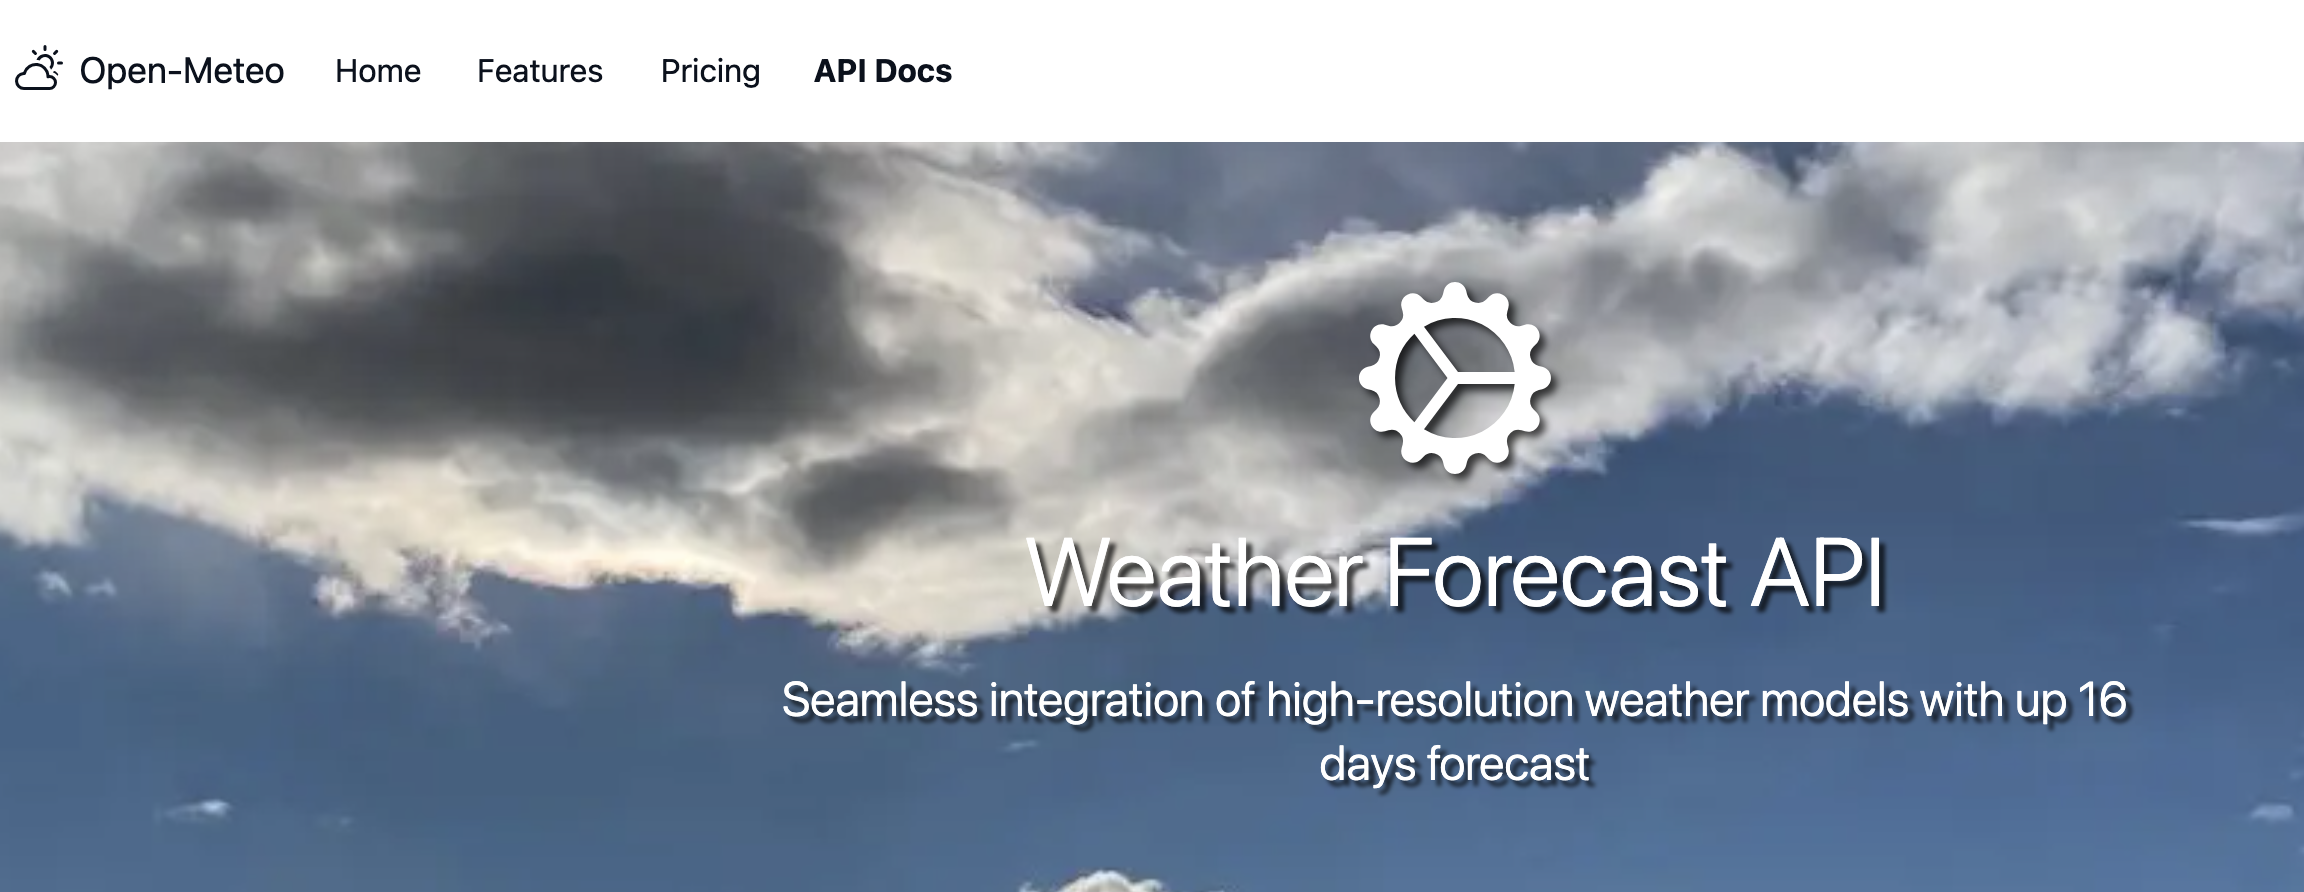

https://open-meteo.com/

In [ ]:
# @title
import requests
import json

# obtener el clima actual de Santiago de Chile, para esto usamos parámetros: params
url = "https://api.open-meteo.com/v1/forecast"
params = {
    "latitude": -33.45,
    "longitude": -70.67,
    "current": "temperature_2m,wind_speed_10m,relative_humidity_2m"
}

response = requests.get(url, params=params)
print(f"código de respuesta: {response.status_code}")
print(f"URL final: {response.url}")  # ver cómo se construyó la URL

In [ ]:
# @title
# ver la respuesta completa
data = response.json()
print(json.dumps(data, indent=2))

In [ ]:
# @title
# extraer los datos que nos interesan
current = data['current']
print(f"temperatura: {current['temperature_2m']}°C")
print(f"viento: {current['wind_speed_10m']} km/h")
print(f"humedad: {current['relative_humidity_2m']}%")

### Usar parámetros con requests.get()

En vez de construir la URL a mano, pasamos un diccionario `params`. `requests` arma la URL automáticamente con los `?` y `&`. Es más limpio y evita errores.

In [ ]:
# @title
# consultar varias ciudades
import time

ciudades = {
    "Santiago": (-33.45, -70.67),
    "Buenos Aires": (-34.61, -58.38),
    "Lima": (-12.05, -77.04),
    "Bogotá": (4.71, -74.07),
    "São Paulo": (-23.55, -46.63)
}

resultados = []
for ciudad, (lat, lon) in ciudades.items():
    params = {
        "latitude": lat,
        "longitude": lon,
        "current": "temperature_2m,wind_speed_10m,relative_humidity_2m"
    }
    response = requests.get(url, params=params)
    if response.status_code == 200:
        current = response.json()['current']
        resultados.append({
            "ciudad": ciudad,
            "temperatura": current['temperature_2m'],
            "viento": current['wind_speed_10m'],
            "humedad": current['relative_humidity_2m']
        })
        print(f"{ciudad}: {current['temperature_2m']}°C, viento {current['wind_speed_10m']} km/h")
    time.sleep(0.5)  # pausa entre solicitudes

# convertir a DataFrame
df_clima = pd.DataFrame(resultados)
df_clima


## 6. Manejo de errores y buenas prácticas

In [ ]:
# @title
# siempre verificar el código de respuesta antes de procesar
response = requests.get("https://api.open-meteo.com/v1/forecast", params={"latitude": 999})

if response.status_code == 200:
    print("datos recibidos")
else:
    print(f"error: código {response.status_code}")
    print(f"detalle: {response.text[:200]}")

### Códigos de respuesta HTTP comunes

| Código | Significado |
| --- | --- |
| 200 | OK — todo bien |
| 400 | Solicitud inválida — parámetros incorrectos |
| 403 | Prohibido — falta User-Agent o API key |
| 404 | No encontrado — URL o recurso inexistente |
| 429 | Demasiadas solicitudes — hacer requests más lento |
| 500 | Error del servidor — problema de ellos, no tuyo |

### Buenas prácticas

- **User-Agent**: incluirlo siempre en scraping (`headers={"User-Agent": "Mozilla/5.0"}`).
- **Pausas**: `time.sleep()` entre solicitudes para no sobrecargar el servidor.
- **Verificar**: revisar `status_code` antes de procesar la respuesta.
- **Parámetros**: usar el diccionario `params` de requests en vez de construir URLs a mano.


## 7. Pipeline completo: scraping + API → SQLite

Combinemos todo: scrapeamos una tabla de Wikipedia, enriquecemos con datos de la API de clima, y guardamos en una base de datos.

In [ ]:
# @title
import pandas as pd
import requests
import sqlite3
import os
import time

# paso 1: scrapear capitales sudamericanas desde Wikipedia
url_wiki = "https://en.wikipedia.org/wiki/List_of_South_American_countries_by_population"
tablas = pd.read_html(url_wiki, storage_options={'User-Agent': 'Mozilla/5.0'})
df_wiki = tablas[0]
print(f"datos scrapeados: {len(df_wiki)} filas")
df_wiki.head()

In [ ]:
# @title
# paso 2: definir coordenadas de capitales para la API de clima
# (en un caso real se podrían scrapear de otra tabla o usar geocoding)
capitales = {
    "Brazil": ("Brasília", -15.78, -47.93),
    "Colombia": ("Bogotá", 4.71, -74.07),
    "Argentina": ("Buenos Aires", -34.61, -58.38),
    "Peru": ("Lima", -12.05, -77.04),
    "Venezuela": ("Caracas", 10.49, -66.88),
    "Chile": ("Santiago", -33.45, -70.67),
    "Ecuador": ("Quito", -0.18, -78.47),
    "Bolivia": ("La Paz", -16.50, -68.15),
    "Paraguay": ("Asunción", -25.26, -57.58),
    "Uruguay": ("Montevideo", -34.88, -56.17),
    "Guyana": ("Georgetown", 6.80, -58.16),
    "Suriname": ("Paramaribo", 5.87, -55.17)
}

In [ ]:
# @title
# paso 3: obtener clima de cada capital desde la API
url_api = "https://api.open-meteo.com/v1/forecast"
datos_clima = []

for pais, (capital, lat, lon) in capitales.items():
    params = {
        "latitude": lat,
        "longitude": lon,
        "current": "temperature_2m,wind_speed_10m,relative_humidity_2m"
    }
    response = requests.get(url_api, params=params)
    if response.status_code == 200:
        current = response.json()['current']
        datos_clima.append({
            "pais": pais,
            "capital": capital,
            "lat": lat,
            "lon": lon,
            "temperatura": current['temperature_2m'],
            "viento": current['wind_speed_10m'],
            "humedad": current['relative_humidity_2m']
        })
        print(f"{capital}: {current['temperature_2m']}°C")
    time.sleep(0.5)

df_clima = pd.DataFrame(datos_clima)
print(f"\ndatos de clima obtenidos: {len(df_clima)} capitales")

In [ ]:
# @title
# paso 4: guardar en SQLite
if os.path.exists('sudamerica.db'):
    os.remove('sudamerica.db')

connection = sqlite3.connect('sudamerica.db')
cursor = connection.cursor()
cursor.execute("PRAGMA foreign_keys = ON")

cursor.execute("""CREATE TABLE Paises(
    pid INTEGER PRIMARY KEY,
    nombre TEXT NOT NULL,
    capital TEXT,
    lat REAL,
    lon REAL
)""")

cursor.execute("""CREATE TABLE Clima(
    cid INTEGER PRIMARY KEY,
    pais_id INTEGER NOT NULL,
    temperatura REAL,
    viento REAL,
    humedad REAL,
    FOREIGN KEY (pais_id) REFERENCES Paises(pid)
)""")

connection.commit()
print("tablas creadas")

In [ ]:
# @title
# cargar datos
paises_map = {}
pid = 1
for _, row in df_clima.iterrows():
    cursor.execute("INSERT INTO Paises(nombre, capital, lat, lon) VALUES (?,?,?,?)",
                   (row['pais'], row['capital'], row['lat'], row['lon']))
    paises_map[row['pais']] = pid

    cursor.execute("INSERT INTO Clima(pais_id, temperatura, viento, humedad) VALUES (?,?,?,?)",
                   (pid, row['temperatura'], row['viento'], row['humedad']))
    pid += 1

connection.commit()
print("datos cargados")

In [ ]:
# @title
# paso 5: consultar
cursor.execute("""
    SELECT P.nombre, P.capital, C.temperatura, C.viento, C.humedad
    FROM Paises P
    JOIN Clima C ON P.pid = C.pais_id
    ORDER BY C.temperatura DESC
""")
print("capitales ordenadas por temperatura (mayor a menor):\n")
for r in cursor.fetchall():
    print(f"{r[1]} ({r[0]}): {r[2]}°C, viento {r[3]} km/h, humedad {r[4]}%")

connection.close()